In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

In [2]:
CSV_PATH = "../../outputs/metadata/sequences_labeled.csv"  # o "/ruta/completa/sequences_labeled.csv"

assert os.path.exists(CSV_PATH), f"No encuentro el archivo: {CSV_PATH}"
df = pd.read_csv(CSV_PATH)

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
df.head()

Filas: 12371
Columnas: 30


,sequence_id,person_global_id,scene_x,cam_id_x,cycle_index,rgb_dir,silhouette_dir,num_frames,frame_start,frame_end,frame_numbers_json,cam_id_y,scene_y,illum_mean,illum_std,contrast_mean,area_mean,fill_mean,fill_median,border_frac,bbox_h_median,bbox_w_median,n_samples_rgb,n_samples_sil,illum_label,illum_variability,expected_fill,fill_norm,occlusion_label,truncation_flag
0,S01_c001_ID0000_cyc0001,0,S01,c001,1,rgb/ID0000/S01/c001/cycle0001,silhouette/ID0000/S01/c001/cycle0001,25,36,60,"[36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 4...",c001,S01,68.036043,7.483206,35.120012,124504.08,0.421804,0.441449,0.64,839.0,361.0,25,25,baja,variable,0.571029,0.773076,parcial,1
1,S01_c001_ID0000_cyc0002,0,S01,c001,2,rgb/ID0000/S01/c001/cycle0002,silhouette/ID0000/S01/c001/cycle0002,25,56,80,"[56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 6...",c001,S01,70.494266,5.033490,39.228609,161129.28,0.483073,0.455384,0.76,807.0,418.0,25,25,baja,variable,0.571029,0.797480,parcial,1
2,S01_c001_ID0000_cyc0003,0,S01,c001,3,rgb/ID0000/S01/c001/cycle0003,silhouette/ID0000/S01/c001/cycle0003,25,76,100,"[76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 8...",c001,S01,78.046173,3.057606,47.925260,141609.12,0.680535,0.713142,0.92,618.0,342.0,25,25,baja,estable,0.571029,1.248871,sin_occlusion,1
3,S01_c001_ID0000_cyc0004,0,S01,c001,4,rgb/ID0000/S01/c001/cycle0004,silhouette/ID0000/S01/c001/cycle0004,25,139,163,"[139, 140, 141, 142, 143, 144, 145, 146, 147, ...",c001,S01,92.395421,5.597164,56.827991,134222.64,0.738190,0.727106,1.00,543.0,347.0,25,25,baja,variable,0.571029,1.273326,sin_occlusion,1
4,S01_c001_ID0000_cyc0005,0,S01,c001,5,rgb/ID0000/S01/c001/cycle0005,silhouette/ID0000/S01/c001/cycle0005,25,195,219,"[195, 196, 197, 198, 199, 200, 201, 202, 203, ...",c001,S01,122.649942,5.229498,66.162216,148583.52,0.462953,0.466822,0.56,726.0,461.0,25,25,media,variable,0.571029,0.817511,parcial,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12371 entries, 0 to 12370
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sequence_id         12371 non-null  object 
 1   person_global_id    12371 non-null  int64  
 2   scene_x             12371 non-null  object 
 3   cam_id_x            12371 non-null  object 
 4   cycle_index         12371 non-null  int64  
 5   rgb_dir             12371 non-null  object 
 6   silhouette_dir      12371 non-null  object 
 7   num_frames          12371 non-null  int64  
 8   frame_start         12371 non-null  int64  
 9   frame_end           12371 non-null  int64  
 10  frame_numbers_json  12371 non-null  object 
 11  cam_id_y            12371 non-null  object 
 12  scene_y             12371 non-null  object 
 13  illum_mean          12371 non-null  float64
 14  illum_std           12371 non-null  float64
 15  contrast_mean       12371 non-null  float64
 16  area

In [4]:
df.columns.tolist()

['sequence_id',
 'person_global_id',
 'scene_x',
 'cam_id_x',
 'cycle_index',
 'rgb_dir',
 'silhouette_dir',
 'num_frames',
 'frame_start',
 'frame_end',
 'frame_numbers_json',
 'cam_id_y',
 'scene_y',
 'illum_mean',
 'illum_std',
 'contrast_mean',
 'area_mean',
 'fill_mean',
 'fill_median',
 'border_frac',
 'bbox_h_median',
 'bbox_w_median',
 'n_samples_rgb',
 'n_samples_sil',
 'illum_label',
 'illum_variability',
 'expected_fill',
 'fill_norm',
 'occlusion_label',
 'truncation_flag']

In [5]:
expected = [
    "sequence_id",
    "illum_mean", "illum_std", "illum_label", "illum_variability",
    "area_mean", "visible_ratio", "occlusion_label",
]
present_expected = [c for c in expected if c in df.columns]
missing_expected = [c for c in expected if c not in df.columns]

print("Columnas esperadas presentes:", present_expected)
print("Columnas esperadas faltantes:", missing_expected)

Columnas esperadas presentes: ['sequence_id', 'illum_mean', 'illum_std', 'illum_label', 'illum_variability', 'area_mean', 'occlusion_label']
Columnas esperadas faltantes: ['visible_ratio']


In [6]:
if "sequence_id" in df.columns:
    dup = df["sequence_id"].duplicated().sum()
    print("Duplicados por sequence_id:", dup)
else:
    print("No existe 'sequence_id' para validar duplicados.")

Duplicados por sequence_id: 0


In [7]:
na_counts = df.isna().sum().sort_values(ascending=False)
na_pct = (na_counts / len(df) * 100).round(2)
na_table = pd.DataFrame({"na_count": na_counts, "na_pct": na_pct})
na_table.head(30)

,na_count,na_pct
sequence_id,0,0.0
person_global_id,0,0.0
occlusion_label,0,0.0
fill_norm,0,0.0
expected_fill,0,0.0
illum_variability,0,0.0
illum_label,0,0.0
n_samples_sil,0,0.0
n_samples_rgb,0,0.0
bbox_w_median,0,0.0


In [8]:
for col in ["illum_mean", "illum_std", "contrast_mean", "area_mean", "visible_ratio"]:
    if col in df.columns:
        s = df[col]
        print(f"\n[{col}] min={np.nanmin(s):.4f}  p1={np.nanpercentile(s.dropna(),1):.4f}  "
              f"p50={np.nanpercentile(s.dropna(),50):.4f}  p99={np.nanpercentile(s.dropna(),99):.4f}  max={np.nanmax(s):.4f}")


[illum_mean] min=21.8118  p1=38.7960  p50=114.9139  p99=219.0472  max=235.5877

[illum_std] min=0.0296  p1=0.1199  p50=2.6624  p99=14.5658  max=74.1561

[contrast_mean] min=14.8653  p1=26.5930  p50=63.2954  p99=89.7202  max=98.5214

[area_mean] min=484.2800  p1=994.2800  p50=50048.1600  p99=279413.0960  max=350440.1600


In [9]:
if "visible_ratio" in df.columns:
    out_of_range = df[(df["visible_ratio"].notna()) & ((df["visible_ratio"] < 0) | (df["visible_ratio"] > 1.5))]
    print("visible_ratio fuera de [0, 1.5]:", len(out_of_range))
    display(out_of_range.head(10))

In [10]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

Numéricas: ['person_global_id', 'cycle_index', 'num_frames', 'frame_start', 'frame_end', 'illum_mean', 'illum_std', 'contrast_mean', 'area_mean', 'fill_mean', 'fill_median', 'border_frac', 'bbox_h_median', 'bbox_w_median', 'n_samples_rgb', 'n_samples_sil', 'expected_fill', 'fill_norm', 'truncation_flag']
Categóricas: ['sequence_id', 'scene_x', 'cam_id_x', 'rgb_dir', 'silhouette_dir', 'frame_numbers_json', 'cam_id_y', 'scene_y', 'illum_label', 'illum_variability', 'occlusion_label']


In [11]:
df[num_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
person_global_id,12371.0,14.043489,18.477548,0.000000,0.000000,0.000000,2.000000,6.000000,11.000000,61.000000,71.000000,73.000000
cycle_index,12371.0,89.045671,105.252113,1.000000,1.000000,4.000000,19.000000,53.000000,112.000000,306.000000,517.300000,641.000000
num_frames,12371.0,25.000000,0.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000,25.000000
frame_start,12371.0,5419.150513,3946.466005,1.000000,115.700000,542.500000,2262.500000,4616.000000,7828.000000,13449.500000,15604.400000,18006.000000
frame_end,12371.0,5443.196104,3946.466673,25.000000,139.700000,566.500000,2286.500000,4640.000000,7852.000000,13473.500000,15628.400000,18030.000000
illum_mean,12371.0,121.424400,41.743115,21.811767,38.796030,58.322221,93.956382,114.913898,142.661468,206.709649,219.047236,235.587674
illum_std,12371.0,3.468625,3.220204,0.029615,0.119942,0.242672,1.368253,2.662353,4.610412,9.311254,14.565795,74.156091
contrast_mean,12371.0,62.183218,15.277243,14.865345,26.592991,35.930131,51.031960,63.295443,74.337067,85.363778,89.720193,98.521417
area_mean,12371.0,78051.195609,78587.165025,484.280000,994.280000,1875.140000,7362.400000,50048.160000,136045.400000,222439.180000,279413.096000,350440.160000
fill_mean,12371.0,0.489690,0.073220,0.195061,0.297617,0.363610,0.443658,0.496821,0.535668,0.604529,0.664611,0.825699


In [12]:
key_cats = [c for c in ["illum_label", "illum_variability", "occlusion_label"] if c in df.columns]
for c in key_cats:
    print(f"\nDistribución: {c}")
    display(df[c].value_counts(dropna=False).to_frame("count").assign(pct=lambda x: (x["count"]/len(df)*100).round(2)))


Distribución: illum_label


,count,pct
illum_label,,
media,6185,50.0
baja,3093,25.0
alta,3093,25.0



Distribución: illum_variability


,count,pct
illum_variability,,
estable,9278,75.0
variable,3093,25.0



Distribución: occlusion_label


,count,pct
occlusion_label,,
sin_occlusion,5257,42.49
parcial,4913,39.71
alta,2201,17.79


In [13]:
def hist_plot(series: pd.Series, title: str, bins: int = 40):
    series = series.dropna()
    if series.empty:
        print(f"Sin datos para {title}")
        return
    plt.figure()
    plt.hist(series.values, bins=bins)
    plt.title(title)
    plt.xlabel(series.name)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

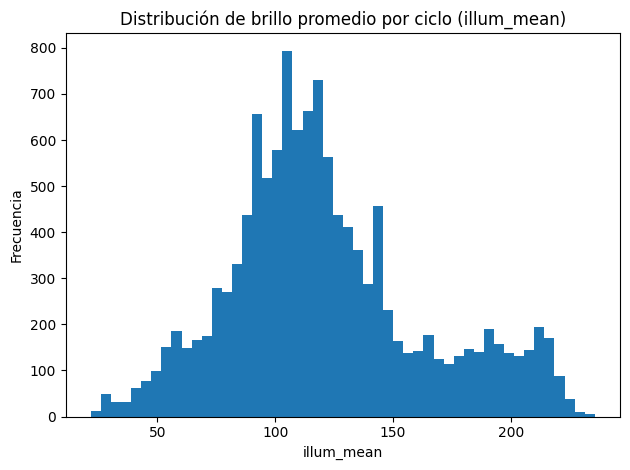

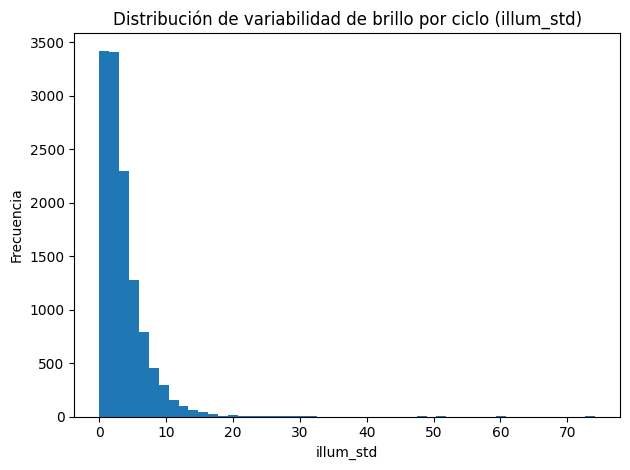

In [14]:
if "illum_mean" in df.columns:
    hist_plot(df["illum_mean"], "Distribución de brillo promedio por ciclo (illum_mean)", bins=50)

if "illum_std" in df.columns:
    hist_plot(df["illum_std"], "Distribución de variabilidad de brillo por ciclo (illum_std)", bins=50)

if "visible_ratio" in df.columns:
    hist_plot(df["visible_ratio"], "Distribución del ratio de área visible (visible_ratio)", bins=50)

In [15]:
def bar_plot_counts(series: pd.Series, title: str):
    vc = series.value_counts(dropna=False)
    plt.figure()
    plt.bar(vc.index.astype(str), vc.values)
    plt.title(title)
    plt.xlabel(series.name)
    plt.ylabel("Conteo")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

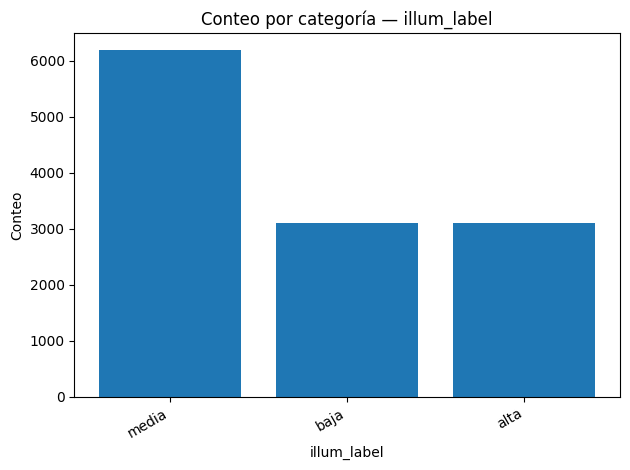

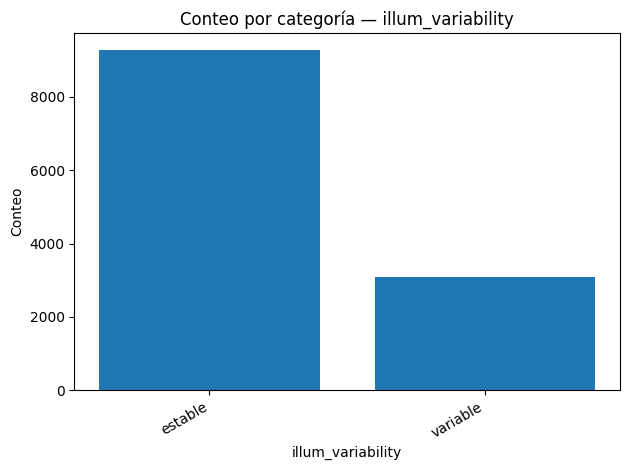

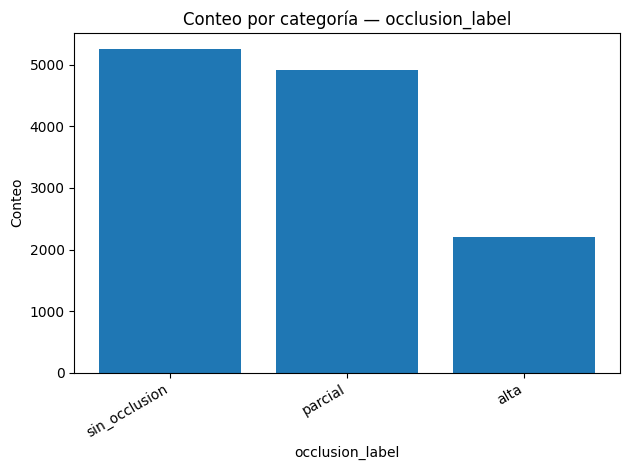

In [16]:
for c in key_cats:
    bar_plot_counts(df[c], f"Conteo por categoría — {c}")

In [17]:
if {"illum_label", "occlusion_label"}.issubset(df.columns):
    ctab = pd.crosstab(df["illum_label"], df["occlusion_label"], dropna=False, normalize=False)
    ctab_pct = pd.crosstab(df["illum_label"], df["occlusion_label"], dropna=False, normalize="index") * 100
    print("Conteos (illum_label x occlusion_label):")
    display(ctab)
    print("Porcentaje por fila (normalizado por illum_label):")
    display(ctab_pct.round(2))

Conteos (illum_label x occlusion_label):


occlusion_label,alta,parcial,sin_occlusion
illum_label,,,
alta,445,1357,1291
baja,867,1152,1074
media,889,2404,2892


Porcentaje por fila (normalizado por illum_label):


occlusion_label,alta,parcial,sin_occlusion
illum_label,,,
alta,14.39,43.87,41.74
baja,28.03,37.25,34.72
media,14.37,38.87,46.76


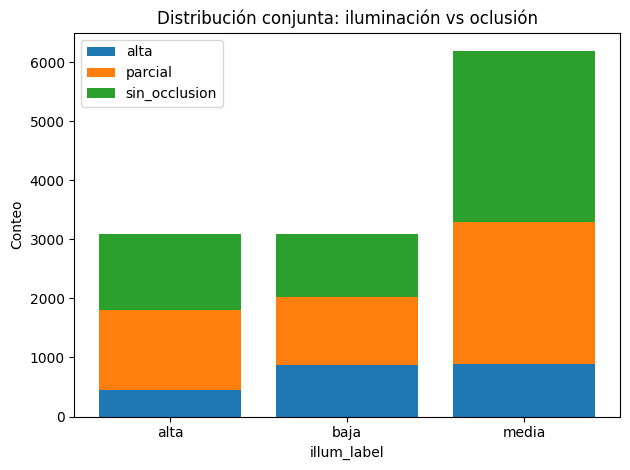

In [18]:
if {"illum_label", "occlusion_label"}.issubset(df.columns):
    ctab = pd.crosstab(df["illum_label"], df["occlusion_label"], dropna=False)
    plt.figure()
    bottom = np.zeros(len(ctab))
    x = np.arange(len(ctab.index))
    for col in ctab.columns:
        plt.bar(x, ctab[col].values, bottom=bottom, label=str(col))
        bottom += ctab[col].values
    plt.title("Distribución conjunta: iluminación vs oclusión")
    plt.xticks(x, ctab.index.astype(str), rotation=0)
    plt.xlabel("illum_label")
    plt.ylabel("Conteo")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [19]:
def summarize_group_counts(df: pd.DataFrame, col: str, topn: int = 20):
    if col not in df.columns:
        print(f"No existe columna '{col}'")
        return
    vc = df[col].value_counts(dropna=False)
    print(f"\n[{col}] únicos={vc.shape[0]}  total={vc.sum()}")
    display(vc.head(topn).to_frame("count").assign(pct=lambda x: (x["count"]/len(df)*100).round(2)))

In [20]:
candidate_cols = ["person_id", "id", "identity_id", "camera_id", "cam_id", "scene_id", "scene", "source"]
for c in candidate_cols:
    if c in df.columns:
        summarize_group_counts(df, c, topn=15)

In [21]:
id_col = None
for c in ["person_id", "identity_id", "id"]:
    if c in df.columns:
        id_col = c
        break

if id_col:
    seq_per_id = df.groupby(id_col)["sequence_id"].nunique() if "sequence_id" in df.columns else df.groupby(id_col).size()
    seq_per_id = seq_per_id.sort_values(ascending=False)
    print(f"IDs únicos: {seq_per_id.shape[0]}")
    display(seq_per_id.describe(percentiles=[0.01,0.05,0.1,0.25,0.5,0.75,0.9,0.95,0.99]).to_frame("seqs_per_id"))
    
    # Histograma #secuencias por ID
    plt.figure()
    plt.hist(seq_per_id.values, bins=50)
    plt.title(f"Distribución: #secuencias por ID ({id_col})")
    plt.xlabel("#secuencias por ID")
    plt.ylabel("Frecuencia (IDs)")
    plt.tight_layout()
    plt.show()
else:
    print("No se encontró una columna de ID de persona (person_id/identity_id/id).")

No se encontró una columna de ID de persona (person_id/identity_id/id).


In [22]:
if {"illum_label", "illum_mean"}.issubset(df.columns):
    display(df.groupby("illum_label")["illum_mean"].agg(["count","mean","std","min","median","max"]).sort_values("mean"))

if {"occlusion_label", "visible_ratio"}.issubset(df.columns):
    display(df.groupby("occlusion_label")["visible_ratio"].agg(["count","mean","std","min","median","max"]).sort_values("mean"))

,count,mean,std,min,median,max
illum_label,,,,,,
baja,3093,74.176882,16.904899,21.811767,78.756987,93.955894
media,6185,115.807465,13.008790,93.956869,114.913898,142.650231
alta,3093,179.903970,25.094198,142.672705,180.504461,235.587674


In [23]:
import random
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [24]:
FRAMES_CSV_PATH = "../../outputs/metadata/sequence_frames.csv"   # <-- cambia si tu archivo se llama distinto o está en otra ruta
BASE_DIR = "D:/tesis_dev/result1/outputs"                            # <-- raíz para resolver rutas relativas de rgb_path/silhouette_path

# Parámetros de inspección
N_CYCLES_PER_COMBO = 3     # n ciclos aleatorios por combinación (illum_label x occlusion_label)
FRAMES_PER_CYCLE = 4       # cuántos frames mostrar por ciclo (muestreados uniformemente)
SHOW_SILHOUETTE = True     # mostrar silueta si existe la ruta

In [25]:
frames_df = None
if Path(FRAMES_CSV_PATH).exists():
    frames_df = pd.read_csv(FRAMES_CSV_PATH)
    print("Frames CSV cargado:", FRAMES_CSV_PATH, "| filas:", len(frames_df), "| cols:", len(frames_df.columns))
else:
    print(f"No se encontró {FRAMES_CSV_PATH}. Se mostrará solo la tabla de ciclos. "
          f"Si quieres inspección visual, define FRAMES_CSV_PATH correctamente.")

Frames CSV cargado: ../../outputs/metadata/sequence_frames.csv | filas: 309275 | cols: 8


In [26]:
def _read_img(path: str, grayscale: bool = False):
    """Lee imagen usando OpenCV. Devuelve np.ndarray o None."""
    flag = cv2.IMREAD_GRAYSCALE if grayscale else cv2.IMREAD_COLOR
    img = cv2.imread(path, flag)
    return img

def _safe_join(base_dir: str, rel_or_abs: str) -> str:
    p = Path(rel_or_abs)
    if p.is_absolute():
        return str(p)
    return str(Path(base_dir) / p)

def _uniform_sample_indices(n: int, k: int):
    if n <= 0:
        return []
    if n <= k:
        return list(range(n))
    return list(np.linspace(0, n - 1, num=k, dtype=int))

def sample_cycles_by_combinations(
    cycles_df: pd.DataFrame,
    n_per_combo: int = 3,
    seed: int = 123,
    illum_col: str = "illum_label",
    occ_col: str = "occlusion_label",
):
    """Devuelve un DF con ciclos muestreados de distintas combinaciones (illum x occlusion)."""
    rnd = np.random.RandomState(seed)
    if illum_col not in cycles_df.columns or occ_col not in cycles_df.columns:
        raise ValueError(f"Faltan columnas {illum_col} y/o {occ_col} en sequences_labeled.csv")

    combos = (
        cycles_df[[illum_col, occ_col]]
        .dropna()
        .drop_duplicates()
        .values
        .tolist()
    )

    sampled_rows = []
    for illum, occ in combos:
        subset = cycles_df[(cycles_df[illum_col] == illum) & (cycles_df[occ_col] == occ)]
        if subset.empty:
            continue
        take = min(n_per_combo, len(subset))
        idx = rnd.choice(subset.index.values, size=take, replace=False)
        sampled_rows.append(cycles_df.loc[idx])

    if len(sampled_rows) == 0:
        return cycles_df.iloc[0:0].copy()

    out = pd.concat(sampled_rows, axis=0).reset_index(drop=True)
    # Barajar para inspección variada
    out = out.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return out

In [27]:
if {"illum_label", "occlusion_label"}.issubset(df.columns):
    sampled_cycles = sample_cycles_by_combinations(
        df,
        n_per_combo=N_CYCLES_PER_COMBO,
        illum_col="illum_label",
        occ_col="occlusion_label",
    )
    print("Ciclos muestreados:", len(sampled_cycles))
    display(sampled_cycles[["sequence_id", "illum_label", "occlusion_label", "illum_mean", "illum_std", "visible_ratio"]]
            if set(["sequence_id","illum_label","occlusion_label","illum_mean","illum_std","visible_ratio"]).issubset(sampled_cycles.columns)
            else sampled_cycles.head(20))
else:
    sampled_cycles = None
    print("No existen columnas illum_label/occlusion_label en el dataframe.")

Ciclos muestreados: 27


,sequence_id,person_global_id,scene_x,cam_id_x,cycle_index,rgb_dir,silhouette_dir,num_frames,frame_start,frame_end,frame_numbers_json,cam_id_y,scene_y,illum_mean,illum_std,contrast_mean,area_mean,fill_mean,fill_median,border_frac,bbox_h_median,bbox_w_median,n_samples_rgb,n_samples_sil,illum_label,illum_variability,expected_fill,fill_norm,occlusion_label,truncation_flag
0,S16_c005_ID0063_cyc0007,63,S16,c005,7,rgb/ID0063/S16/c005/cycle0007,silhouette/ID0063/S16/c005/cycle0007,25,7587,7611,"[7587, 7588, 7589, 7590, 7591, 7592, 7593, 759...",c005,S16,155.518800,2.419317,68.344353,3404.96,0.476413,0.460168,0.00,129.0,56.0,25,25,alta,estable,0.539617,0.852767,parcial,0
1,S05_c001_ID0007_cyc0067,7,S05,c001,67,rgb/ID0007/S05/c001/cycle0067,silhouette/ID0007/S05/c001/cycle0067,25,4665,4689,"[4665, 4666, 4667, 4668, 4669, 4670, 4671, 467...",c001,S05,75.538322,5.161278,50.467440,61666.04,0.584784,0.655746,0.20,456.0,200.0,25,25,baja,variable,0.571029,1.148358,sin_occlusion,0
2,S01_c002_ID0002_cyc0140,2,S01,c002,140,rgb/ID0002/S01/c002/cycle0140,silhouette/ID0002/S01/c002/cycle0140,25,9948,9972,"[9948, 9949, 9950, 9951, 9952, 9953, 9954, 995...",c002,S01,107.434683,7.006451,64.270448,38348.32,0.459050,0.442132,0.00,441.0,189.0,25,25,media,variable,0.554288,0.797657,parcial,0
3,S04_c002_ID0004_cyc0030,4,S04,c002,30,rgb/ID0004/S04/c002/cycle0030,silhouette/ID0004/S04/c002/cycle0030,25,1177,1201,"[1177, 1178, 1179, 1180, 1181, 1182, 1183, 118...",c002,S04,130.217575,4.987472,67.240019,30103.04,0.442923,0.459251,0.00,423.0,153.0,25,25,media,variable,0.554288,0.828541,parcial,0
4,S09_c004_ID0026_cyc0001,26,S09,c004,1,rgb/ID0026/S09/c004/cycle0001,silhouette/ID0026/S09/c004/cycle0001,25,5216,5240,"[5216, 5217, 5218, 5219, 5220, 5221, 5222, 522...",c004,S09,223.416781,2.000788,46.510979,1035.12,0.352183,0.349375,0.40,80.0,39.0,25,25,alta,estable,0.546485,0.639313,alta,1
5,S02_c001_ID0002_cyc0042,2,S02,c001,42,rgb/ID0002/S02/c001/cycle0042,silhouette/ID0002/S02/c001/cycle0042,25,2647,2671,"[2647, 2648, 2649, 2650, 2651, 2652, 2653, 265...",c001,S02,101.722777,11.070216,57.365033,121863.68,0.378951,0.375565,0.00,810.0,411.0,25,25,media,variable,0.571029,0.657698,alta,0
6,S01_c003_ID0001_cyc0067,1,S01,c003,67,rgb/ID0001/S01/c003/cycle0067,silhouette/ID0001/S01/c003/cycle0067,25,5335,5359,"[5335, 5336, 5337, 5338, 5339, 5340, 5341, 534...",c003,S01,147.396733,2.408896,55.537379,38680.88,0.546090,0.544819,0.00,495.0,157.0,25,25,alta,estable,0.619374,0.879628,parcial,0
7,S09_c004_ID0016_cyc0016,16,S09,c004,16,rgb/ID0016/S09/c004/cycle0016,silhouette/ID0016/S09/c004/cycle0016,25,2077,2101,"[2077, 2078, 2079, 2080, 2081, 2082, 2083, 208...",c004,S09,143.996467,8.456199,85.268793,11183.36,0.544029,0.537807,0.00,237.0,87.0,25,25,alta,variable,0.546485,0.984121,sin_occlusion,0
8,S09_c004_ID0027_cyc0077,27,S09,c004,77,rgb/ID0027/S09/c004/cycle0077,silhouette/ID0027/S09/c004/cycle0077,25,7834,7858,"[7834, 7835, 7836, 7837, 7838, 7839, 7840, 784...",c004,S09,30.815164,0.342051,26.850712,37710.00,0.268718,0.268070,1.00,507.0,277.0,25,25,baja,estable,0.546485,0.490535,alta,1
9,S17_c004_ID0064_cyc0016,64,S17,c004,16,rgb/ID0064/S17/c004/cycle0016,silhouette/ID0064/S17/c004/cycle0016,25,1358,1382,"[1358, 1359, 1360, 1361, 1362, 1363, 1364, 136...",c004,S17,189.763622,4.304754,80.086360,4013.00,0.409605,0.409259,0.00,162.0,60.0,25,25,alta,estable,0.546485,0.748894,alta,0


In [28]:
def show_cycle_frames(
    sequence_id,
    cycles_row: pd.Series,
    frames_df: pd.DataFrame,
    base_dir: str,
    frames_per_cycle: int = 4,
    show_silhouette: bool = True,
):
    """
    Muestra FRAMES_PER_CYCLE frames RGB (y opcional siluetas) de un cycle (sequence_id).
    """
    g = frames_df[frames_df["sequence_id"] == sequence_id].copy()
    if g.empty:
        print(f"[WARN] No hay frames para sequence_id={sequence_id}")
        return

    # Si hay columna de orden temporal, úsala; si no, deja el orden del CSV
    for order_col in ["frame_idx", "frame_id", "t", "timestamp"]:
        if order_col in g.columns:
            g = g.sort_values(order_col)
            break

    idxs = _uniform_sample_indices(len(g), frames_per_cycle)
    g_s = g.iloc[idxs].reset_index(drop=True)

    # Preparar figura: 1 fila por tipo (RGB / SIL) y columnas = frames
    ncols = len(g_s)
    nrows = 2 if (show_silhouette and "silhouette_path" in g_s.columns) else 1

    fig_w = max(12, 3 * ncols)
    fig_h = 4 * nrows
    plt.figure(figsize=(fig_w, fig_h))

    # Título con etiquetas
    illum = cycles_row.get("illum_label", "NA")
    occ = cycles_row.get("occlusion_label", "NA")
    illum_mean = cycles_row.get("illum_mean", np.nan)
    vis_ratio = cycles_row.get("visible_ratio", np.nan)
    plt.suptitle(
        f"sequence_id={sequence_id} | illum={illum} (mean={illum_mean:.2f}) | occlusion={occ} (ratio={vis_ratio:.2f})",
        y=1.02
    )

    def _plot_at(r, c, img, gray=False, title=None):
        ax = plt.subplot(nrows, ncols, r * ncols + c + 1)
        if img is None:
            ax.text(0.5, 0.5, "NO IMG", ha="center", va="center")
            ax.axis("off")
            return
        if gray:
            ax.imshow(img, cmap="gray")
        else:
            # OpenCV carga BGR; convertir a RGB para matplotlib
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if title:
            ax.set_title(title, fontsize=10)
        ax.axis("off")

    for j, row in g_s.iterrows():
        # RGB
        if "rgb_path" in row and pd.notna(row["rgb_path"]):
            rgb_path = _safe_join(base_dir, str(row["rgb_path"]))
            rgb = _read_img(rgb_path, grayscale=False)
        else:
            rgb = None
        _plot_at(0, j, rgb, gray=False, title=f"RGB {j+1}")

        # SIL
        if nrows == 2:
            if "silhouette_path" in row and pd.notna(row["silhouette_path"]):
                sil_path = _safe_join(base_dir, str(row["silhouette_path"]))
                sil = _read_img(sil_path, grayscale=True)
            else:
                sil = None
            _plot_at(1, j, sil, gray=True, title=f"SIL {j+1}")

    plt.tight_layout()
    plt.show()

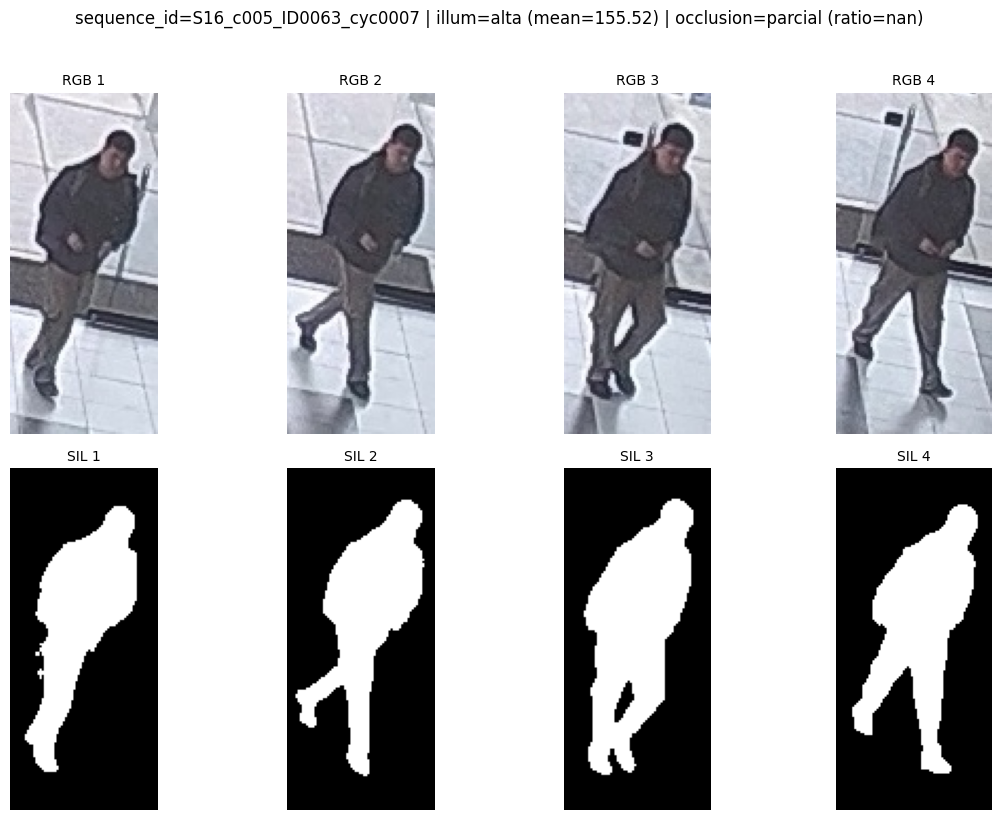

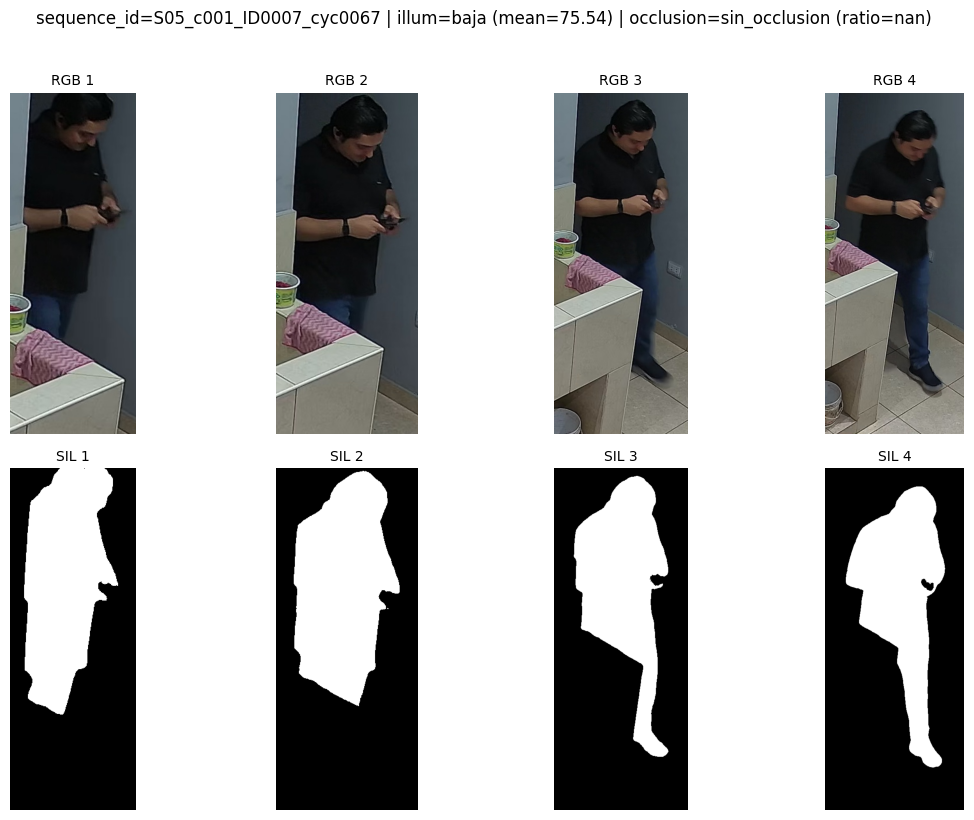

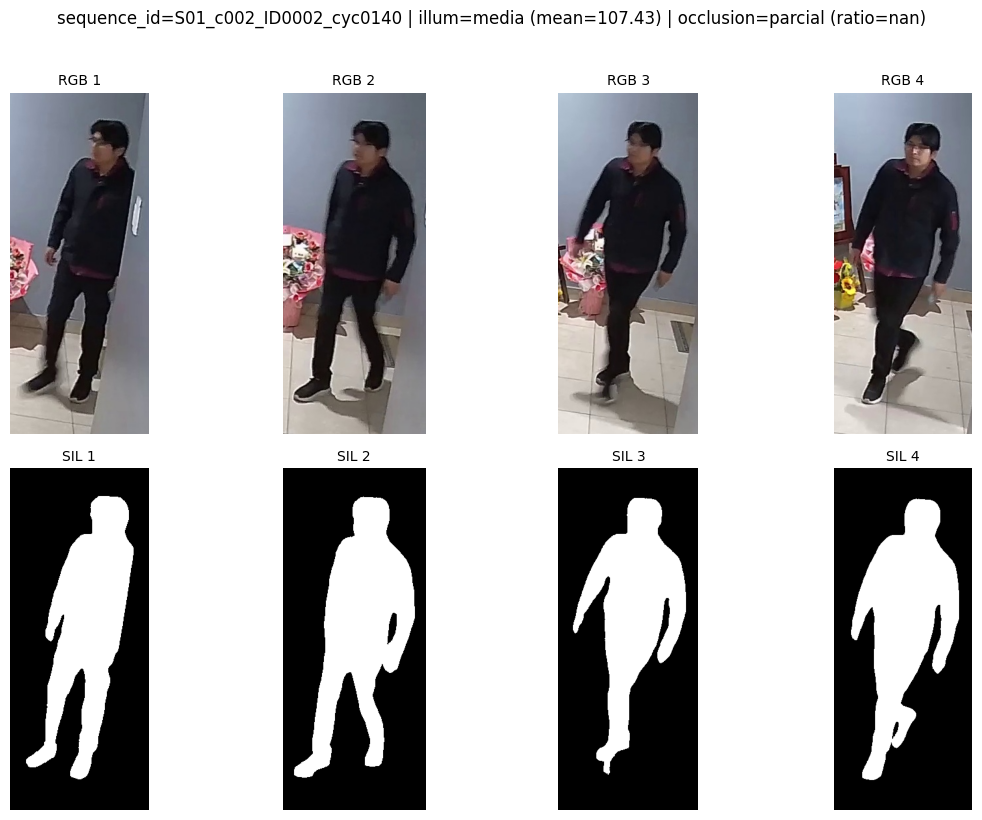

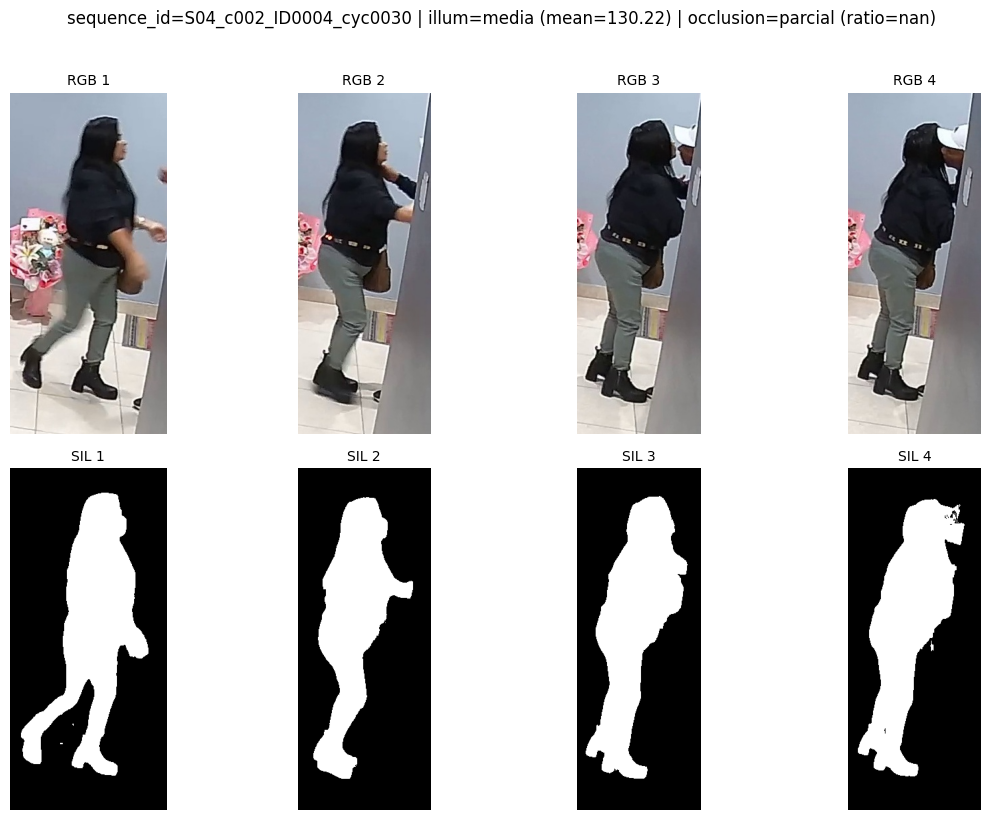

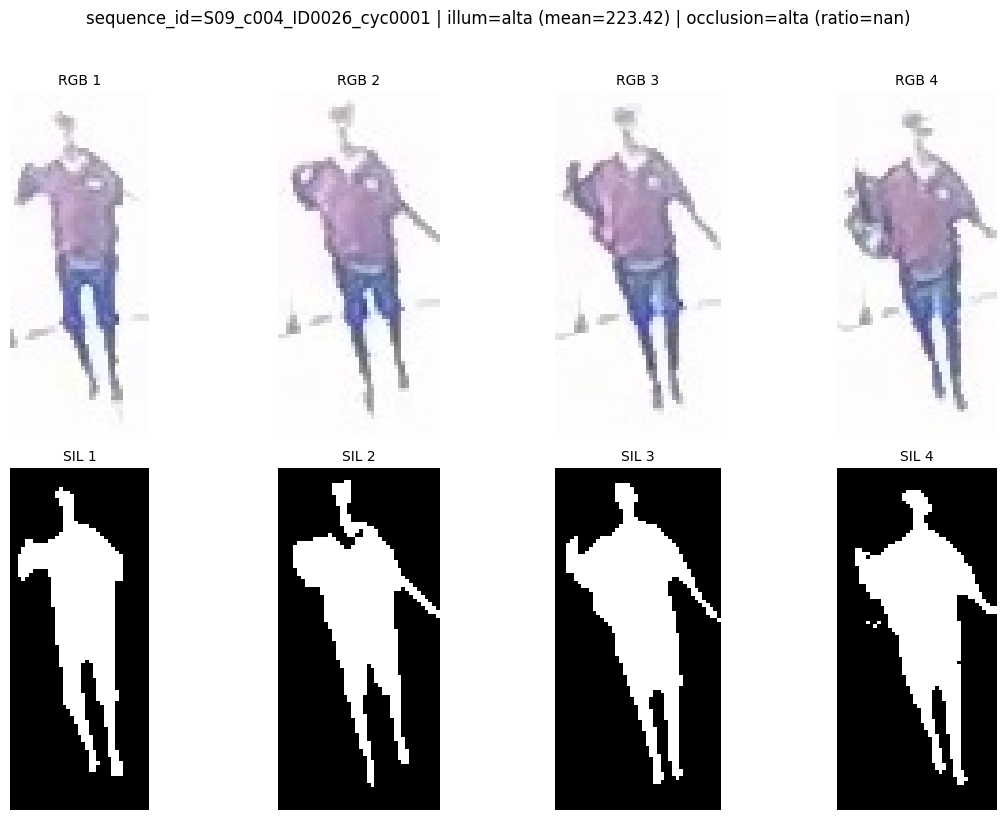

In [29]:
MAX_CYCLES_TO_SHOW = 5

if sampled_cycles is not None and frames_df is not None:
    # Validar columnas mínimas en frames_df
    needed = {"sequence_id", "rgb_path"}
    if not needed.issubset(frames_df.columns):
        print(f"frames_df no tiene columnas mínimas {needed}. Columnas actuales:", frames_df.columns.tolist())
    else:
        to_show = sampled_cycles.head(MAX_CYCLES_TO_SHOW)

        for _, cyc in to_show.iterrows():
            seq_id = cyc["sequence_id"] if "sequence_id" in cyc else None
            if seq_id is None or pd.isna(seq_id):
                continue
            show_cycle_frames(
                sequence_id=seq_id,
                cycles_row=cyc,
                frames_df=frames_df,
                base_dir=BASE_DIR,
                frames_per_cycle=FRAMES_PER_CYCLE,
                show_silhouette=SHOW_SILHOUETTE,
            )
else:
    print("No se puede hacer inspección visual (falta sampled_cycles o frames_df).")